# Deep Learning

## Embedding based routine

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow.keras as keras

In [58]:
df = pd.read_csv("../../../data/train.txt", delimiter=';', names=['text', 'emotion'])
df.head()

,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [59]:
from nltk.tokenize import WordPunctTokenizer

tokenizer = WordPunctTokenizer()
tokenized_text = tokenizer.tokenize(' '.join(df.text))

vocab = set(tokenized_text)
vocab_size = len(vocab)
print("Size of vocabulary is", vocab_size)

Size of vocabulary is 15212


In [60]:
from nltk.probability import FreqDist

fd = FreqDist(tokenized_text)
pd.DataFrame(fd.most_common(), columns=['word', 'common']).iloc[::1000, :]

,word,common
0,i,25859
1000,throw,30
2000,lunch,10
3000,guitar,6
4000,imagination,4
5000,sensory,3
6000,medal,2
7000,heights,2
8000,chocolating,1
9000,dubya,1


In [61]:
vocab = [w for w,_ in fd.most_common()[:6000]]
id2str = {i:token for i, token in enumerate(vocab)}
str2id = {token:i for i, token in enumerate(vocab)}
print("Token mappings with ids done")

Token mappings with ids done


In [62]:
# few left out chars
# pad chars, unknown chars, truncate chars
vocab_size = len(vocab)

# id starts from zero
str2id['<pad>'] = vocab_size
str2id['<unk>'] = vocab_size + 1
str2id['<...>'] = vocab_size + 2

id2str[vocab_size] = '<pad>'
id2str[vocab_size + 1] = '<unk>'
id2str[vocab_size + 2] = '<...>'

In [63]:
def sentence_to_tokens(sentence: str):
    buffer = []
    for token in tokenizer.tokenize(sentence):
        buffer.append(str2id.get(token, str2id['<unk>']))
    return buffer

# we are not explicitly working on reverse process
# i.e. conversion of back to sentence
# why? we don't care! :)
# chill, its a classification problem

In [64]:
length_of_tokens = df['text'].apply(sentence_to_tokens).apply(len)

print("Min tokens are", length_of_tokens.min())
print("Avg tokens are", length_of_tokens.mean())
print("Mdn tokens are", length_of_tokens.median())
print("Std tokens are", length_of_tokens.std())
print("Max tokens are", length_of_tokens.max())

Min tokens are 2
Avg tokens are 19.1663125
Mdn tokens are 17.0
Std tokens are 10.986904575759887
Max tokens are 66


In [65]:
MAX_LEN = 50


def sentence_to_tokens(sentence: str):
    tokens = tokenizer.tokenize(sentence)
    token_ids = [str2id.get(token, str2id["<unk>"]) for token in tokens]
    if len(token_ids) > MAX_LEN:
        token_ids = token_ids[: MAX_LEN - 1] + [str2id["<...>"]]

    elif len(token_ids) < MAX_LEN:
        token_ids = token_ids + [str2id["<pad>"]] * (MAX_LEN - len(token_ids))

    return token_ids

In [66]:
# EMBEDDING MODEL 

embedding_model_input = keras.Input(
    shape=(None,), 
    dtype="int32", 
    name="Embedding Input"
)
x = keras.layers.Embedding(
    input_dim=len(str2id), 
    output_dim=256
)(embedding_model_input)
embedding_model_output = x

embedding_model = keras.Model(
    embedding_model_input,
    embedding_model_output,
    name="Embeddings"
)
embedding_model.summary()

Model: "Embeddings"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Embedding Input (InputLayer)    │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, None, 256)      │     1,536,768 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,536,768 (5.86 MB)

 Trainable params: 1,536,768 (5.86 MB)

 Non-trainable params: 0 (0.00 B)

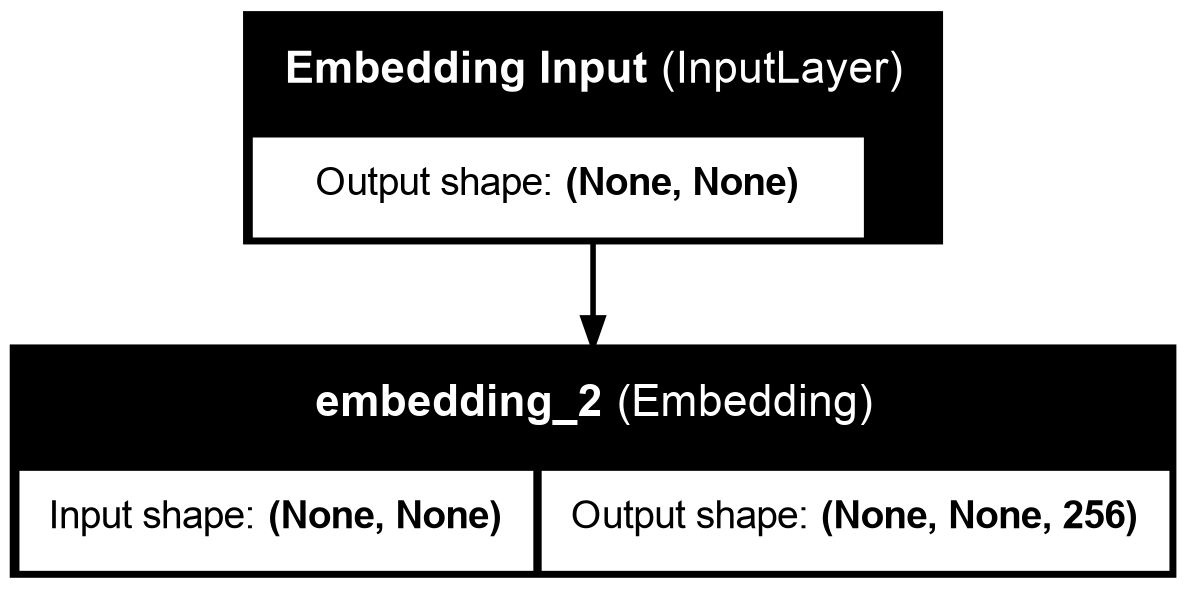

In [67]:
keras.utils.plot_model(
    embedding_model, 
    show_layer_names=True,
    show_shapes=True
)

In [68]:
# preparing input data
X = np.array(
    df['text'].apply(
        sentence_to_tokens
    ).tolist()
)
X

array([[   0,  137,    1, ..., 6000, 6000, 6000],
       [   0,   38,   99, ..., 6000, 6000, 6000],
       [  15, 3058,    5, ..., 6000, 6000, 6000],
       ...,
       [   0,    1,  325, ..., 6000, 6000, 6000],
       [   0,    1,   12, ..., 6000, 6000, 6000],
       [   0,   45,    5, ..., 6000, 6000, 6000]], shape=(16000, 50))

In [69]:
embedding_model.compile(
    optimizer = 'adam',
    loss = {
        embedding_model_output.name : keras.losses.CategoricalCrossentropy()
    },
    loss_weights = {
        embedding_model_output.name : 1.0
    }
)

In [70]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['emotion'])

In [71]:
num_classes = len(label_encoder.classes_)

model = keras.Sequential(
    [
        embedding_model,
        keras.layers.GlobalAveragePooling1D(), 
        keras.layers.Dropout(0.3),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(num_classes, activation="softmax"),
    ],
    name="Learner"
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "Learner"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Embeddings (Functional)         │ (None, None, 256)      │     1,536,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,553,606 (5.93 MB)

 Trainable params: 1,553,606 (5.93 MB)

 Non-trainable params: 0 (0.00 B)

In [72]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [50]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, y_val),
)

Epoch 1/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 14s 32ms/step - accuracy: 0.3429 - loss: 1.5844 - val_accuracy: 0.4309 - val_loss: 1.5374
Epoch 2/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.4748 - loss: 1.3874 - val_accuracy: 0.5575 - val_loss: 1.1627
Epoch 3/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.7295 - loss: 0.8073 - val_accuracy: 0.8156 - val_loss: 0.6179
Epoch 4/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.8691 - loss: 0.4150 - val_accuracy: 0.8400 - val_loss: 0.4451
Epoch 5/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 21s 32ms/step - accuracy: 0.9090 - loss: 0.2827 - val_accuracy: 0.8578 - val_loss: 0.4234
Epoch 6/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.9312 - loss: 0.2186 - val_accuracy: 0.8662 - val_loss: 0.3915
Epoch 7/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - accuracy: 0.9440 - loss: 0.1764 - val_accuracy: 0.8744 - val_loss: 0.4117
Epoch 8/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.9534 - loss: 0.1469 - 

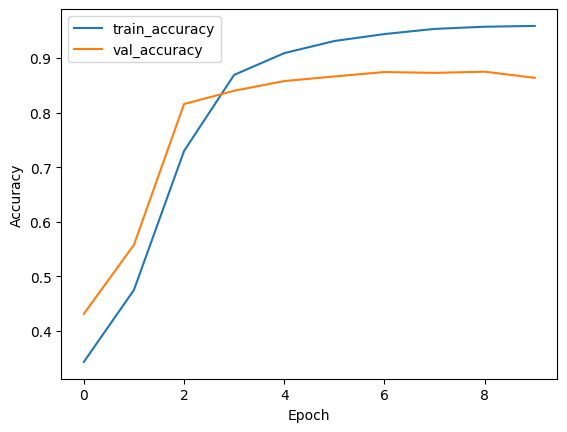

In [51]:
plt.plot(history.history["accuracy"], label="train_accuracy")
plt.plot(history.history["val_accuracy"], label="val_accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [52]:
def predict_emotion(sentence: str):
    tokens = sentence_to_tokens(sentence)
    input_array = np.array([tokens])

    preds = model.predict(input_array)[0]
    predicted_class_id = np.argmax(preds)

    emotion = label_encoder.inverse_transform([predicted_class_id])[0]
    confidence = preds[predicted_class_id]

    return emotion, confidence

In [53]:
test_df = pd.read_csv("../../../data/test.txt", delimiter=';', names=['text', 'emotion'])
test_df.head()

,text,emotion
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [54]:
Test_X = np.array(test_df["text"].apply(sentence_to_tokens).tolist())
Test_X

array([[  15,    6,  201, ..., 6000, 6000, 6000],
       [  15, 6001,    9, ..., 6000, 6000, 6000],
       [   0,  143,   78, ..., 6000, 6000, 6000],
       ...,
       [   0,    1,    7, ..., 6000, 6000, 6000],
       [  15,    6,   36, ..., 6000, 6000, 6000],
       [   0,    1,   34, ..., 6000, 6000, 6000]], shape=(2000, 50))

In [55]:
Test_y = label_encoder.transform(test_df.emotion.tolist())
Test_y

array([4, 4, 4, ..., 2, 2, 1], shape=(2000,))

In [56]:
test_loss, test_acc = model.evaluate(Test_X, Test_y)
print(f"Test Accuracy: {test_acc:.2%}")


from sklearn.metrics import classification_report

y_pred_probs = model.predict(Test_X)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(Test_y, y_pred, target_names=label_encoder.classes_))

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8615 - loss: 0.4195
Test Accuracy: 86.15%
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
              precision    recall  f1-score   support

       anger       0.85      0.88      0.86       275
        fear       0.86      0.83      0.84       224
         joy       0.85      0.92      0.89       695
        love       0.71      0.80      0.75       159
     sadness       0.96      0.83      0.89       581
    surprise       0.70      0.67      0.68        66

    accuracy                           0.86      2000
   macro avg       0.82      0.82      0.82      2000
weighted avg       0.87      0.86      0.86      2000



## General ML workflow

### TFIDF Hack

In [77]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, stop_words="english")

X_train_tfidf = tfidf.fit_transform(df["text"])
Test_X_tfidf = tfidf.transform(test_df["text"])

y_train = label_encoder.transform(df["emotion"])
Test_y = label_encoder.transform(test_df["emotion"])

In [78]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# Fit on training data
rf_model.fit(X_train_tfidf, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [79]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = rf_model.predict(Test_X_tfidf)

acc = accuracy_score(Test_y, y_pred)
print(f"Random Forest Test Accuracy: {acc:.2%}\n")

print(
    classification_report(Test_y, y_pred, target_names=label_encoder.classes_)
)

Random Forest Test Accuracy: 88.75%

              precision    recall  f1-score   support

       anger       0.90      0.91      0.90       275
        fear       0.84      0.91      0.88       224
         joy       0.89      0.92      0.90       695
        love       0.77      0.73      0.75       159
     sadness       0.95      0.91      0.93       581
    surprise       0.71      0.59      0.64        66

    accuracy                           0.89      2000
   macro avg       0.84      0.83      0.83      2000
weighted avg       0.89      0.89      0.89      2000



In [88]:
label_encoder.inverse_transform(rf_model.predict(tfidf.transform(["It looks funny but its actually sad."])))[0]

'surprise'

### Dumb RF

In [80]:
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(df["emotion"])
Test_y = label_encoder.transform(test_df["emotion"])

rf_dumb = RandomForestClassifier(
    n_estimators=100, random_state=42, n_jobs=-1
)

In [82]:
rf_dumb.fit(X, y_train)

y_pred = rf_dumb.predict(Test_X)

acc = accuracy_score(Test_y, y_pred)
print(f"🌲 'Dumb' Random Forest Accuracy: {acc:.2%}\n")

print(
    classification_report(Test_y, y_pred, target_names=label_encoder.classes_)
)

🌲 'Dumb' Random Forest Accuracy: 34.80%

              precision    recall  f1-score   support

       anger       0.17      0.03      0.04       275
        fear       0.14      0.02      0.03       224
         joy       0.37      0.68      0.48       695
        love       0.15      0.01      0.02       159
     sadness       0.33      0.36      0.34       581
    surprise       0.00      0.00      0.00        66

    accuracy                           0.35      2000
   macro avg       0.19      0.18      0.15      2000
weighted avg       0.28      0.35      0.28      2000

